# Shift sensitivity diagnostic (no training)

Uses only the **internal test** split (labelled, never trained on) and one trained checkpoint.
It makes the internal test images sharper, blurrier, brighter etc. by the amounts we measured on the Kaggle images and checks how much accuracy drops.
Kaggle images are only used for unlabeled confidence statistics, the same as the earlier diagnostic.

Runs on CPU or GPU in a few minutes. Set `RUN_NAME` to the checkpoint you want to test, then Run all.

In [2]:
RUN_NAME = "resnet_w64-128-256_b443_ta_ema_cutmix_sam_v1"   # model to diagnose (folder under runs/)
DRIVE_PROJECT_DIR = "cifar10_resnet_challenge"

import os, glob, json, math
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import torchvision.transforms.v2.functional as TF
import matplotlib.pyplot as plt
try:
    from google.colab import drive; drive.mount("/content/drive")
    DRIVE_ROOT = os.path.join("/content/drive/MyDrive", DRIVE_PROJECT_DIR)
except ImportError:
    DRIVE_ROOT = os.path.abspath(os.path.join(os.environ.get("DRIVE_ROOT_OVERRIDE", "./drive_sim"), DRIVE_PROJECT_DIR))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = torch.bfloat16 if device.type == "cuda" else None
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
print("device:", device, "| project:", DRIVE_ROOT)

Mounted at /content/drive
device: cuda | project: /content/drive/MyDrive/cifar10_resnet_challenge


In [3]:
# ---- model definitions (same as the training notebook) ----
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut = nn.Identity()
        if stride != 1 or cin != cout:
            self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x), inplace=True)

class CifarResNet(nn.Module):
    def __init__(self, widths=(64, 128, 256), blocks=(3, 3, 3), num_classes=10, dropout=0.0):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True))
        layers, cin = [], widths[0]
        for i, (w, nb) in enumerate(zip(widths, blocks)):
            for j in range(nb):
                layers.append(BasicBlock(cin, w, 2 if (j == 0 and i > 0) else 1)); cin = w
        self.layers = nn.Sequential(*layers); self.drop = nn.Dropout(dropout); self.fc = nn.Linear(cin, num_classes)
    def forward(self, x):
        x = self.layers(self.stem(x))
        return self.fc(self.drop(torch.flatten(F.adaptive_avg_pool2d(x, 1), 1)))

class ResNeXtBlock(nn.Module):
    def __init__(self, cin, inner, cout, stride, cardinality):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, inner, 1, bias=False); self.bn1 = nn.BatchNorm2d(inner)
        self.conv2 = nn.Conv2d(inner, inner, 3, stride, 1, groups=cardinality, bias=False); self.bn2 = nn.BatchNorm2d(inner)
        self.conv3 = nn.Conv2d(inner, cout, 1, bias=False); self.bn3 = nn.BatchNorm2d(cout)
        self.shortcut = nn.Identity()
        if stride != 1 or cin != cout:
            self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = F.relu(self.bn2(self.conv2(out)), inplace=True)
        out = self.bn3(self.conv3(out))
        return F.relu(out + self.shortcut(x), inplace=True)

class ResNeXt29(nn.Module):
    def __init__(self, cardinality=2, bottleneck_width=64, blocks=(3, 3, 3), out_widths=(256, 512, 1024), num_classes=10, dropout=0.0, stem=64):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, stem, 3, 1, 1, bias=False), nn.BatchNorm2d(stem), nn.ReLU(inplace=True))
        layers, cin = [], stem
        for i, (cout, nb) in enumerate(zip(out_widths, blocks)):
            inner = cardinality * bottleneck_width * (2 ** i)
            for j in range(nb):
                layers.append(ResNeXtBlock(cin, inner, cout, 2 if (j == 0 and i > 0) else 1, cardinality)); cin = cout
        self.layers = nn.Sequential(*layers); self.drop = nn.Dropout(dropout); self.fc = nn.Linear(cin, num_classes)
    def forward(self, x):
        x = self.layers(self.stem(x))
        return self.fc(self.drop(torch.flatten(F.adaptive_avg_pool2d(x, 1), 1)))

def build_model(c):
    if c.get("ARCH", "resnet") == "resnet":
        return CifarResNet(c["WIDTHS"], c["BLOCKS"], dropout=c.get("DROPOUT", 0.0))
    return ResNeXt29(c.get("CARDINALITY", 2), c.get("BOTTLENECK_WIDTH", 64), c.get("BLOCKS", (3, 3, 3)), c.get("WIDTHS", (256, 512, 1024)), dropout=c.get("DROPOUT", 0.0))

In [4]:
# ---- load checkpoint, internal test split, Kaggle test images ----
ck = torch.load(os.path.join(DRIVE_ROOT, "runs", RUN_NAME, "best.pt"), map_location=device, weights_only=False)
cfg = ck["cfg"]
model = build_model(cfg).to(device).to(memory_format=torch.channels_last)
model.load_state_dict(ck["model"]); model.eval()
MEAN = ck["norm"]["mean"].to(device); STD = ck["norm"]["std"].to(device)
print(f"loaded {RUN_NAME}: epoch {ck['epoch']}, val {ck['val_acc']:.4f}, params {sum(p.numel() for p in model.parameters()):,}")

cache = os.path.join(DRIVE_ROOT, "data", "cache")
X_full = np.load(os.path.join(cache, "train_x.npy")); y_full = np.load(os.path.join(cache, "train_y.npy"))
X_kag = np.load(os.path.join(cache, "test_x.npy"))
split = os.path.join(DRIVE_ROOT, "data", "splits",
                     f"split_seed{cfg['SPLIT_SEED']}_val{cfg['VAL_FRAC']}_test{cfg['TEST_FRAC']}_n{len(y_full)}.npz")
te_idx = np.load(split)["test"]
to_t = lambda a: torch.from_numpy(a).permute(0, 3, 1, 2).contiguous().to(device)
Xte, yte, Xk = to_t(X_full[te_idx]), torch.from_numpy(y_full[te_idx]).to(device), to_t(X_kag)
print("internal test:", tuple(Xte.shape), "| kaggle:", tuple(Xk.shape))

@torch.no_grad()
def probs(X_u8, bs=500, tta=True):
    out = []
    for i in range(0, len(X_u8), bs):
        x = ((X_u8[i:i + bs].float() / 255 - MEAN) / STD).contiguous(memory_format=torch.channels_last)
        with torch.autocast(device.type, dtype=AMP or torch.float32, enabled=AMP is not None):
            p = model(x).float().softmax(1)
            if tta: p = (p + model(x.flip(3)).float().softmax(1)) / 2
        out.append(p)
    return torch.cat(out)

def lap_var(X_u8):
    g = (X_u8.float() / 255 * torch.tensor([0.299, 0.587, 0.114], device=X_u8.device).view(1, 3, 1, 1)).sum(1)
    l = 4 * g[:, 1:-1, 1:-1] - g[:, :-2, 1:-1] - g[:, 2:, 1:-1] - g[:, 1:-1, :-2] - g[:, 1:-1, 2:]
    return l.var(dim=(1, 2)).mean().item()

def summarize(name, X_u8, ref_lap):
    p = probs(X_u8); mp = p.max(1).values
    return {"transform": name, "sharpness x": round(lap_var(X_u8) / ref_lap, 3),
            "acc": round((p.argmax(1) == yte).float().mean().item(), 4),
            "mean max-prob": round(mp.mean().item(), 4), "share max-prob<0.5": round((mp < 0.5).float().mean().item(), 4)}

def sharpen_to(X_u8, target_ratio, ref_lap):
    """Find the adjust_sharpness factor that hits a target Laplacian-variance ratio (works for blur too, target<1)."""
    grid = np.concatenate([np.linspace(0.0, 1.0, 41), np.linspace(1.0, 4.0, 121)])
    best = min(grid, key=lambda f: abs(lap_var(TF.adjust_sharpness(X_u8, float(f))) / ref_lap - target_ratio))
    return TF.adjust_sharpness(X_u8, float(best)), float(best)

loaded resnet_w64-128-256_b443_ta_ema_cutmix_sam_v1: epoch 396, val 0.9784, params 4,697,162
internal test: (2500, 3, 32, 32) | kaggle: (2000, 3, 32, 32)


In [5]:
# ---- 1. sensitivity table ----
ref = lap_var(Xte)
rows = [summarize("clean internal test", Xte, ref)]
for k, ratio in [(1, 1.164), (2, 1.328), (3, 1.492)]:          # 1x / 2x / 3x the measured Kaggle sharpness shift (+16.4%)
    Xs, f = sharpen_to(Xte, ratio, ref); rows.append(summarize(f"sharpen x{k} (factor {f:.2f})", Xs, ref))
for ratio in [0.85, 0.70]:
    Xs, f = sharpen_to(Xte, ratio, ref); rows.append(summarize(f"blur to {ratio:.2f} (factor {f:.2f})", Xs, ref))
rows.append(summarize("brightness x1.035", TF.adjust_brightness(Xte, 1.035), ref))
rows.append(summarize("contrast x1.058", TF.adjust_contrast(Xte, 1.058), ref))
rows.append(summarize("saturation x0.94", TF.adjust_saturation(Xte, 0.94), ref))
for k in (1, 2):
    Xs, _ = sharpen_to(Xte, 1 + 0.164 * k, ref)
    Xs = TF.adjust_saturation(TF.adjust_brightness(TF.adjust_contrast(Xs, 1 + 0.058 * k), 1 + 0.035 * k), 1 - 0.06 * k)
    rows.append(summarize(f"ALL measured shifts x{k}", Xs, ref))
pk = probs(Xk); mpk = pk.max(1).values
rows.append({"transform": "KAGGLE test (reference, no labels)", "sharpness x": round(lap_var(Xk) / ref, 3), "acc": None,
             "mean max-prob": round(mpk.mean().item(), 4), "share max-prob<0.5": round((mpk < 0.5).float().mean().item(), 4)})
res = pd.DataFrame(rows); res["acc change"] = (res["acc"] - res.loc[0, "acc"]).round(4)
pd.set_option("display.width", 200); print(res.to_string(index=False))
print("\nHow to read: if 'sharpen x1' or 'ALL measured shifts x1' costs >= 0.01 accuracy and moves confidence toward the Kaggle row,"
      "\nthe pixel-level shift is part of the gap. If it costs < 0.005, the gap comes from image content, not pixel statistics.")

                         transform  sharpness x    acc  mean max-prob  share max-prob<0.5  acc change
               clean internal test        1.000 0.9732         0.8352              0.0260      0.0000
          sharpen x1 (factor 1.12)        1.149 0.9736         0.8350              0.0268      0.0004
          sharpen x2 (factor 1.27)        1.342 0.9728         0.8346              0.0276     -0.0004
          sharpen x3 (factor 1.38)        1.478 0.9716         0.8342              0.0272     -0.0016
        blur to 0.85 (factor 0.88)        0.862 0.9724         0.8346              0.0252     -0.0008
        blur to 0.70 (factor 0.70)        0.689 0.9708         0.8339              0.0264     -0.0024
                 brightness x1.035        1.072 0.9732         0.8352              0.0260      0.0000
                   contrast x1.058        1.119 0.9736         0.8349              0.0272      0.0004
                  saturation x0.94        1.000 0.9728         0.8351             

67 errors of 2500 (2.68%). Top confusions (true -> predicted):
cat -> dog             11
dog -> cat              7
automobile -> truck     4
horse -> deer           3
bird -> airplane        3
bird -> frog            3
airplane -> ship        3
bird -> cat             3
horse -> dog            2
cat -> bird             2


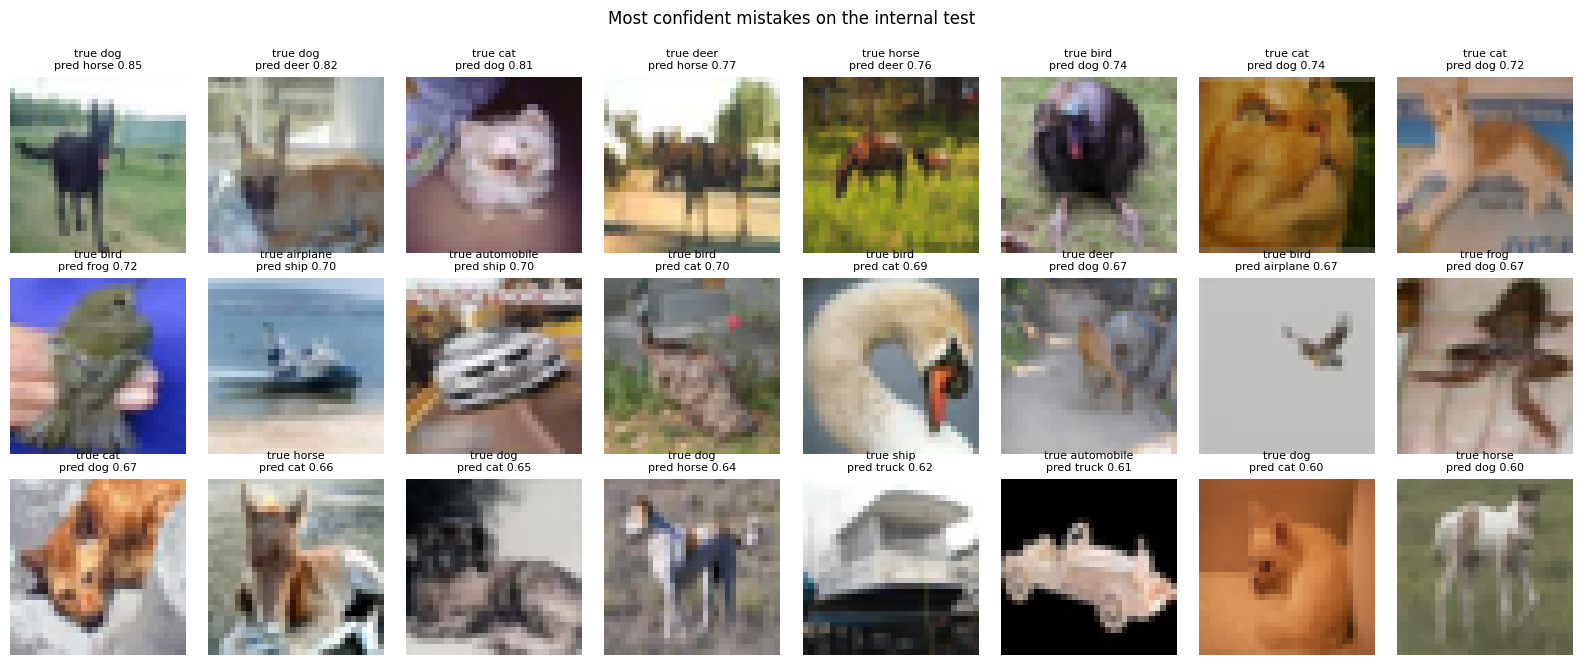

In [6]:
# ---- 2. error analysis on clean internal test ----
p = probs(Xte); pred = p.argmax(1); conf = p.max(1).values
wrong = (pred != yte).nonzero().flatten()
pairs = pd.Series([f"{CLASS_NAMES[t]} -> {CLASS_NAMES[q]}" for t, q in zip(yte[wrong].tolist(), pred[wrong].tolist())]).value_counts()
print(f"{len(wrong)} errors of {len(yte)} ({len(wrong)/len(yte):.2%}). Top confusions (true -> predicted):")
print(pairs.head(10).to_string())

order = wrong[conf[wrong].argsort(descending=True)][:24].cpu().numpy()
fig, axs = plt.subplots(3, 8, figsize=(16, 6.6))
for a, i in zip(axs.flat, order):
    a.imshow(Xte[i].permute(1, 2, 0).cpu().numpy(), interpolation="nearest"); a.axis("off")
    a.set_title(f"true {CLASS_NAMES[yte[i]]}\npred {CLASS_NAMES[pred[i]]} {conf[i]:.2f}", fontsize=8)
plt.suptitle("Most confident mistakes on the internal test", y=1.0); plt.tight_layout(); plt.show()

In [7]:
# ---- 3. how different are two submissions? (paired noise check for the public leaderboard) ----
subs = sorted(glob.glob(os.path.join(DRIVE_ROOT, "runs", "*", "submission_*.csv")))
for s in subs: print(os.path.relpath(s, DRIVE_ROOT))

def compare_subs(a, b, n_public=1000):
    A, B = pd.read_csv(a), pd.read_csv(b)
    assert (A["id"].values == B["id"].values).all()
    d = (A["label"].values != B["label"].values).mean()
    se = math.sqrt(d / n_public)
    print(f"{d:.1%} of predictions differ -> a public-score difference smaller than about {2*se:.3f} is noise")

if len(subs) >= 2:
    compare_subs(subs[-2], subs[-1])   # change the two paths to compare any pair

runs/kd_ens_w64-128-256_b443_sam_v1/submission_20261030_2217_val0.9764_test0.9732.csv
runs/resnet_w64-128-256_b333_aug_v1/submission_20261030_0421_val0.9568_test0.9524.csv
runs/resnet_w64-128-256_b333_noaug_v1/submission_20261030_0404_val0.8964_test0.8992.csv
runs/resnet_w64-128-256_b333_ta_ema_cutmix_v1/submission_20261030_0528_val0.9756_test0.9704.csv
runs/resnet_w64-128-256_b333_ta_v1/submission_20261030_0450_val0.9672_test0.9676.csv
runs/resnet_w64-128-256_b443_ta_ema_cutmix_sam_v1/submission_20261030_1956_val0.9784_test0.9732.csv
7.2% of predictions differ -> a public-score difference smaller than about 0.017 is noise


In [8]:
# ---- 4. TTA comparison: choose on VAL, report on internal test, write Kaggle submission ----
va_idx = np.load(split)["val"]
Xva, yva = to_t(X_full[va_idx]), torch.from_numpy(y_full[va_idx]).to(device)

@torch.no_grad()
def predict_views(X_u8, shifts, flip=True, pad=4, bs=500):
    out = []
    for i in range(0, len(X_u8), bs):
        x = (X_u8[i:i + bs].float() / 255 - MEAN) / STD
        xp = F.pad(x, (pad, pad, pad, pad), mode="reflect"); p = 0
        for dy, dx in shifts:
            v = xp[:, :, pad + dy:pad + dy + 32, pad + dx:pad + dx + 32].contiguous(memory_format=torch.channels_last)
            for f in ([False, True] if flip else [False]):
                with torch.autocast(device.type, dtype=AMP or torch.float32, enabled=AMP is not None):
                    p = p + model(v.flip(3) if f else v).float().softmax(1)
        out.append(p)
    return torch.cat(out)

def corners(s): return [(0, 0), (-s, -s), (-s, s), (s, -s), (s, s)]   # centre + 4 corners
variants = {
    "no TTA (1 view)":             ([(0, 0)], False),
    "flip (2 views)":              ([(0, 0)], True),
    "10-view, corners 1px":        (corners(1), True),
    "10-view, corners 2px":        (corners(2), True),
    "10-view, corners 4px":        (corners(4), True),
    "18-view, 3x3 grid 1px":       ([(dy, dx) for dy in (-1, 0, 1) for dx in (-1, 0, 1)], True),
}
rows = []
for name, (sh, fl) in variants.items():
    va = (predict_views(Xva, sh, fl).argmax(1) == yva).float().mean().item()
    te = (predict_views(Xte, sh, fl).argmax(1) == yte).float().mean().item()
    rows.append({"variant": name, "val acc": round(va, 4), "internal test acc": round(te, 4)})
tta = pd.DataFrame(rows); print(tta.to_string(index=False))

best = tta.loc[tta["val acc"].idxmax(), "variant"]            # chosen on VAL only
print(f"\nchosen on val: {best} | its internal test: {tta.set_index('variant').loc[best, 'internal test acc']:.4f}")
sh, fl = variants[best]
kp = predict_views(Xk, sh, fl).argmax(1).cpu().numpy()
sub = pd.read_csv(os.path.join(cache, "sample_submission.csv"))[["id"]].copy()
assert (sub["id"].values == np.load(os.path.join(cache, "test_ids.npy"))).all()
sub["label"] = kp.astype(int)
out = os.path.join(DRIVE_ROOT, "runs", RUN_NAME, f"submission_tta_{best.split(' (')[0].replace(' ', '').replace(',', '_')}.csv")
sub.to_csv(out, index=False); print("saved:", out)
base = predict_views(Xk, [(0, 0)], True).argmax(1).cpu().numpy()
d = (kp != base).mean()
print(f"differs from plain flip TTA on {d:.1%} of Kaggle predictions -> public-score change below ~{2*math.sqrt(d/1000):.3f} is noise")

              variant  val acc  internal test acc
      no TTA (1 view)   0.9784             0.9704
       flip (2 views)   0.9784             0.9732
 10-view, corners 1px   0.9768             0.9732
 10-view, corners 2px   0.9772             0.9744
 10-view, corners 4px   0.9760             0.9720
18-view, 3x3 grid 1px   0.9760             0.9732

chosen on val: no TTA (1 view) | its internal test: 0.9704
saved: /content/drive/MyDrive/cifar10_resnet_challenge/runs/resnet_w64-128-256_b443_ta_ema_cutmix_sam_v1/submission_tta_noTTA.csv
differs from plain flip TTA on 1.8% of Kaggle predictions -> public-score change below ~0.008 is noise


In [9]:
# ---- 5. Ensemble check: disagreement and averaged accuracy of several runs ----
ENSEMBLE_RUNS = ["resnet_w64-128-256_b443_ta_ema_cutmix_sam_v1",
                 "resnext29_4x24d_ta_ema_cutmix_sam_v1"]

va_idx = np.load(split)["val"]
Xva, yva = to_t(X_full[va_idx]), torch.from_numpy(y_full[va_idx]).to(device)

@torch.no_grad()
def run_probs(m, mean, std, X_u8, bs=500):
    out = []
    for i in range(0, len(X_u8), bs):
        x = ((X_u8[i:i + bs].float() / 255 - mean) / std).contiguous(memory_format=torch.channels_last)
        with torch.autocast(device.type, dtype=AMP or torch.float32, enabled=AMP is not None):
            out.append((m(x).float().softmax(1) + m(x.flip(3)).float().softmax(1)) / 2)
    return torch.cat(out)

P = {}
for rn in ENSEMBLE_RUNS:
    c = torch.load(os.path.join(DRIVE_ROOT, "runs", rn, "best.pt"), map_location=device, weights_only=False)
    m = build_model(c["cfg"]).to(device).to(memory_format=torch.channels_last); m.load_state_dict(c["model"]); m.eval()
    mu, sd = c["norm"]["mean"].to(device), c["norm"]["std"].to(device)
    P[rn] = {"val": run_probs(m, mu, sd, Xva), "test": run_probs(m, mu, sd, Xte), "kaggle": run_probs(m, mu, sd, Xk)}
    del m

def cd_errors(pred, y):
    cat, dog = CLASS_NAMES.index("cat"), CLASS_NAMES.index("dog")
    return int(((y == cat) & (pred == dog)).sum()), int(((y == dog) & (pred == cat)).sum())

rows = []
for rn in ENSEMBLE_RUNS:
    pt = P[rn]["test"].argmax(1)
    rows.append({"model": rn, "val": (P[rn]["val"].argmax(1) == yva).float().mean().item(),
                 "internal test": (pt == yte).float().mean().item(), "errors": int((pt != yte).sum()),
                 "cat->dog, dog->cat": cd_errors(pt, yte)})
ens = {s: sum(P[rn][s] for rn in ENSEMBLE_RUNS) / len(ENSEMBLE_RUNS) for s in ("val", "test", "kaggle")}
pe = ens["test"].argmax(1)
rows.append({"model": f"AVERAGE of {len(ENSEMBLE_RUNS)}", "val": (ens["val"].argmax(1) == yva).float().mean().item(),
             "internal test": (pe == yte).float().mean().item(), "errors": int((pe != yte).sum()),
             "cat->dog, dog->cat": cd_errors(pe, yte)})
print(pd.DataFrame(rows).round(4).to_string(index=False))

names = list(P)
print("\nhow often each pair of models disagrees (internal test / kaggle):")
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        dt = (P[names[i]]["test"].argmax(1) != P[names[j]]["test"].argmax(1)).float().mean().item()
        dk = (P[names[i]]["kaggle"].argmax(1) != P[names[j]]["kaggle"].argmax(1)).float().mean().item()
        print(f"  {names[i][:28]:28s} vs {names[j][:28]:28s}: {dt:.1%} / {dk:.1%}")

                                       model    val  internal test  errors cat->dog, dog->cat
resnet_w64-128-256_b443_ta_ema_cutmix_sam_v1 0.9784         0.9732      67            (11, 7)
        resnext29_4x24d_ta_ema_cutmix_sam_v1 0.9776         0.9736      66             (6, 6)
                                AVERAGE of 2 0.9784         0.9760      60             (7, 5)

how often each pair of models disagrees (internal test / kaggle):
  resnet_w64-128-256_b443_ta_e vs resnext29_4x24d_ta_ema_cutmi: 2.4% / 6.5%
